# Explainable ML for heart failure gene signatures

Main analysis notebook: labelling and QC, top-5,000 variance filter, alignment of the external cohort, Lasso / SVM / Random Forest with a 60/20/20 split and 5-fold grid search (RQ1), external validation on GSE5406 (RQ3), SHAP consensus signatures and the cross-cohort 6-gene panel (RQ2). Run the R preprocessing in `R/` first. Outputs are from the dissertation run.

In [ ]:
# --- CONFIG ---
# Folder holding the inputs from the R preprocessing (GSE57338_Cleaned_Normalized.csv, GSE5406_Cleaned_Normalized.csv,
# GSE57338_Metadata.csv, GSE5406_Metadata.csv). Intermediate CSVs are written here too.
# On Colab with Google Drive: DATA_DIR = "/content/drive/MyDrive/Dissertation"
import os
DATA_DIR = "../data"
RESULTS_DIR = "../results"
os.makedirs(RESULTS_DIR, exist_ok=True)


Loading datasets...
Internal Data (GSE57338): 313 samples, 19997 genes.
External Data (GSE5406):  210 samples, 13631 genes.


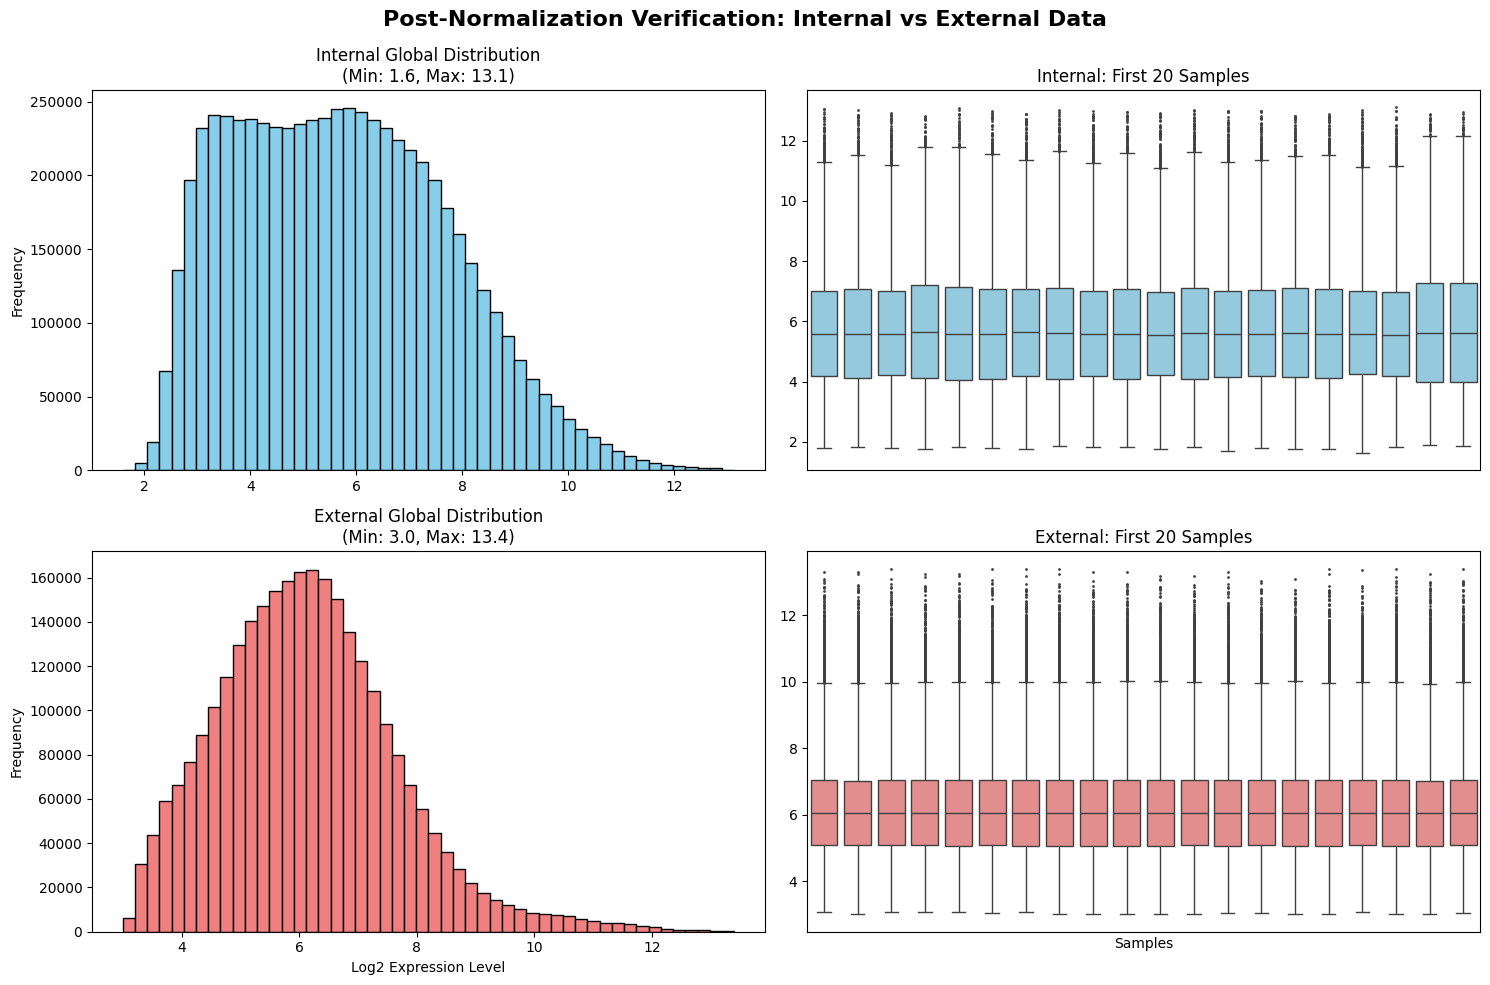

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD THE PRE-NORMALIZED DATA FROM R
print("Loading datasets...")
df_internal = pd.read_csv(f"{DATA_DIR}/GSE57338_Cleaned_Normalized.csv", index_col=0)
df_external = pd.read_csv(f"{DATA_DIR}/GSE5406_Cleaned_Normalized.csv", index_col=0)
X_int = df_internal.select_dtypes(include='number')
X_ext = df_external.select_dtypes(include='number')

print(f"Internal Data (GSE57338): {X_int.shape[1]} samples, {X_int.shape[0]} genes.")
print(f"External Data (GSE5406):  {X_ext.shape[1]} samples, {X_ext.shape[0]} genes.")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Post-Normalization Verification: Internal vs External Data", fontsize=16, fontweight='bold')

# --- ROW 1: INTERNAL DATA (GSE57338) ---
int_values = X_int.values.flatten()

# Plot 1A: Global Histogram
axes[0, 0].hist(int_values, bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title(f"Internal Global Distribution\n(Min: {int_values.min():.1f}, Max: {int_values.max():.1f})")
axes[0, 0].set_ylabel("Frequency")

# Plot 1B: Sample Boxplots (First 20 samples)
# Because genes are rows and samples are columns, we plot directly
sns.boxplot(data=X_int.iloc[:, :20], fliersize=1, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title("Internal: First 20 Samples")
axes[0, 1].set_xticks([]) # Hide messy sample IDs

# --- ROW 2: EXTERNAL DATA (GSE5406) ---
ext_values = X_ext.values.flatten()

# Plot 2A: Global Histogram
axes[1, 0].hist(ext_values, bins=50, color='lightcoral', edgecolor='black')
axes[1, 0].set_title(f"External Global Distribution\n(Min: {ext_values.min():.1f}, Max: {ext_values.max():.1f})")
axes[1, 0].set_xlabel("Log2 Expression Level")
axes[1, 0].set_ylabel("Frequency")

# Plot 2B: Sample Boxplots (First 20 samples)
sns.boxplot(data=X_ext.iloc[:, :20], fliersize=1, ax=axes[1, 1], color='lightcoral')
axes[1, 1].set_title("External: First 20 Samples")
axes[1, 1].set_xlabel("Samples")
axes[1, 1].set_xticks([]) # Hide messy sample IDs

# 3. SHOW PLOT
plt.tight_layout()
# Adjust layout to make room for the master title
plt.subplots_adjust(top=0.90)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# FUNCTION 1: PROCESS AND LABEL DATA
def process_dataset(expr_file, meta_file, meta_id_col, meta_target_col, label_mapping):
    print(f"PROCESSING {expr_file}")

    df_expression = pd.read_csv(expr_file, index_col=0)
    df_meta = pd.read_csv(meta_file)
    print(f"{df_expression.shape[0]} genes, {df_expression.shape[1]} samples")

    df_transposed = df_expression.T
    df_transposed.index = [str(x).split('_')[0] for x in df_transposed.index]

    id_to_disease = dict(zip(df_meta[meta_id_col], df_meta[meta_target_col]))
    df_transposed['Target_Label'] = df_transposed.index.map(id_to_disease)

    df_transposed['Target'] = df_transposed['Target_Label'].map(label_mapping)

    nan_count = df_transposed['Target'].isna().sum()
    if nan_count > 0:
        print(f"{nan_count} samples could not be mapped!")
    else:
        print("Samples successfully mapped to 0 and 1.")

    final_df = df_transposed.drop(columns=['Target_Label'])
    cols = ['Target'] + [col for col in final_df.columns if col != 'Target']
    final_df = final_df[cols]

    return final_df

# FUNCTION 2: QUALITY CONTROL (MISSING VALUES)
def check_missing_values(df_full, dataset_name):
    print(f"\n--- PHASE 2: QUALITY CONTROL ({dataset_name}) ---")

    df_genes = df_full.drop(columns=['Target'])
    total_missing = df_genes.isna().sum().sum()

    if total_missing == 0:
        print("No missing values detected in genes or samples.")
    else:
        print(f"Found {total_missing} missing values.")

# FUNCTION 3: OUTLIER IDENTIFICATION (NO REMOVAL, NO PLOTS)
def identify_outliers(df, dataset_name):
    print(f"PHASE 3: OUTLIER IDENTIFICATION ({dataset_name}) ---")

    X = df.drop(columns=['Target'])

    # Automated Outlier Identification (Statistical)
    print("Calculating Sample Connectivity (Z-Scores)...")
    corr_matrix = X.T.corr()
    mean_connectivity = corr_matrix.mean()
    z_scores = (mean_connectivity - mean_connectivity.mean()) / mean_connectivity.std()

    outlier_threshold = -2.5
    outliers = z_scores[z_scores < outlier_threshold]

    # Report Outliers (But DO NOT Drop Them)
    if len(outliers) > 0:
        print(f"{len(outliers)} Outliers (Z < {outlier_threshold}):")
        print(outliers.index.tolist())
        print("Outliers flagged but kept in the dataset.")
    else:
        print("No statistical outliers found.")

# EXECUTE FULL PIPELINE

# 1. EXTERNAL DATASET (GSE5406)
ext_mapping = {
    'normally functioning myocardium from unused donor heart': 0,           # Control
    'systolic heart failure due to ischemic cardiomyopathy': 1,             # Heart Failure
    'systolic heart failure due to idiopathic dilated cardiomyopathy': 1    # Heart Failure
}

# Run Phase 1
df_ext = process_dataset(
    expr_file=f"{DATA_DIR}/GSE5406_Cleaned_Normalized.csv",
    meta_file=f"{DATA_DIR}/GSE5406_Metadata.csv",
    meta_id_col="geo_accession",
    meta_target_col="characteristics_ch1",
    label_mapping=ext_mapping
)

# Run Phase 2
check_missing_values(df_ext, "External Validation Set")

# Run Phase 3 (Identify only, no plots)
identify_outliers(df_ext, "External Validation Set")

# Save final single file
ext_output = f"{DATA_DIR}/GSE5406_Labeled_Final.csv"
df_ext.to_csv(ext_output)
print(f"\n{ext_output} (Contains ALL samples, shape: {df_ext.shape})")


# 2. INTERNAL DATASET (GSE57338)
int_mapping = {
    'heart left ventricle, non-failing': 0,             # Control
    'heart left ventricle, ischemic': 1,                # Heart Failure
    'heart left ventricle, idiopathic dilated CMP': 1   # Heart Failure
}

# Run Phase 1
df_int = process_dataset(
    expr_file=f"{DATA_DIR}/GSE57338_Cleaned_Normalized.csv",
    meta_file=f"{DATA_DIR}/GSE57338_Metadata.csv",
    meta_id_col="geo_accession",
    meta_target_col="source_name_ch1",    # UPDATED: Changed from characteristics_ch1
    label_mapping=int_mapping
)

# Run Phase 2
check_missing_values(df_int, "Internal Training Set")

# Run Phase 3 (Identify only, no plots)
identify_outliers(df_int, "Internal Training Set")

# Save final single file
int_output = f"{DATA_DIR}/GSE57338_Labeled_Final.csv"
df_int.to_csv(int_output)
print(f"\n[SAVED] {int_output} (Contains ALL samples, shape: {df_int.shape})")

PROCESSING /content/drive/MyDrive/Dissertation/GSE5406_Cleaned_Normalized.csv
13631 genes, 210 samples
Samples successfully mapped to 0 and 1.

--- PHASE 2: QUALITY CONTROL (External Validation Set) ---
No missing values detected in genes or samples.
PHASE 3: OUTLIER IDENTIFICATION (External Validation Set) ---
Calculating Sample Connectivity (Z-Scores)...
7 Outliers (Z < -2.5):
['GSM123534', 'GSM123642', 'GSM123649', 'GSM123707', 'GSM123708', 'GSM123713', 'GSM123719']
Outliers flagged but kept in the dataset.

GSE5406_Labeled_Final.csv (Contains ALL samples, shape: (210, 13632))
PROCESSING /content/drive/MyDrive/Dissertation/GSE57338_Cleaned_Normalized.csv
19997 genes, 313 samples
Samples successfully mapped to 0 and 1.

--- PHASE 2: QUALITY CONTROL (Internal Training Set) ---
No missing values detected in genes or samples.
PHASE 3: OUTLIER IDENTIFICATION (Internal Training Set) ---
Calculating Sample Connectivity (Z-Scores)...
6 Outliers (Z < -2.5):
['GSM1379815', 'GSM1379862', 'GSM1

Original Training Data: 313 samples, 19997 genes
Calculating variance per gene...
Filtered Training Data: 313 samples, 5000 genes
Saved: 'GSE57338_Top5000.csv'

Running dimensionality reduction for visualization... (Close plot window to continue script!)


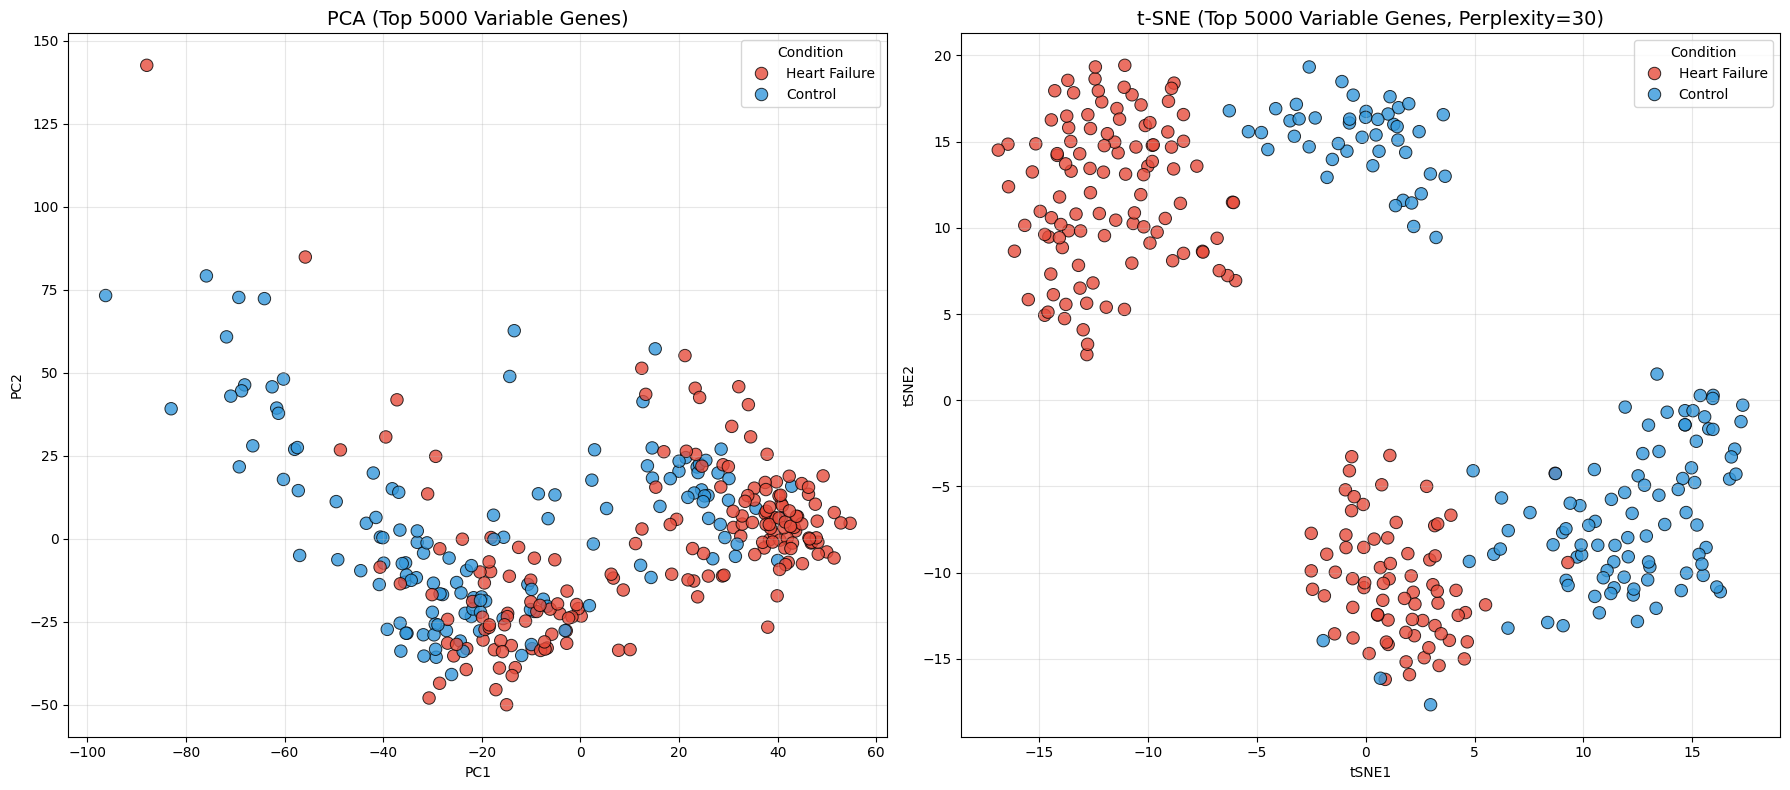


STEP 6: ALIGNING EXTERNAL TEST SET (GSE5406)
Training set features: 5000
Testing set features found: 3410
Testing set features missing (padded with 0): 1590

Final Training Shape: (313, 5001)
Final Testing Shape:  (210, 5001)

 Saved 'GSE5406_Test_Padded.csv'
datasets have identical columns


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(f"{DATA_DIR}/GSE57338_Labeled_Final.csv", index_col=0)

# Separate Target and Genes
y = df['Target']
X = df.drop(columns=['Target'])

print(f"Original Training Data: {X.shape[0]} samples, {X.shape[1]} genes")

# CALCULATE VARIANCE
print("Calculating variance per gene...")
gene_variances = X.var()

# SORT AND SELECT TOP 5000
top_n = 5000
sorted_genes = gene_variances.sort_values(ascending=False)
top_genes_list = sorted_genes.head(top_n).index

# Create the filtered dataset
X_top5000 = X[top_genes_list]

print(f"Filtered Training Data: {X_top5000.shape[0]} samples, {X_top5000.shape[1]} genes")

# STEP 4: SAVE THE FILTERED DATASET
df_top5000 = pd.concat([y, X_top5000], axis=1)

output_train_filename = f"{DATA_DIR}/GSE57338_Top5000.csv"
df_top5000.to_csv(output_train_filename)
print(f"Saved: '{output_train_filename}'")

#  VISUALIZATION CHECK (PCA & t-SNE)
print("\nRunning dimensionality reduction for visualization... (Close plot window to continue script!)")

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_top5000)

# Bulletproof Label Mapping
condition_labels = ['Control' if int(float(val)) == 0 else 'Heart Failure' for val in y]

# Run PCA
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(data=pca_coords, columns=['PC1', 'PC2'], index=X.index)
df_pca['Condition'] = condition_labels

# Run t-SNE
n_samples = X.shape[0]
optimal_perplexity = min(30, max(5, n_samples // 3))

tsne = TSNE(n_components=2, perplexity=optimal_perplexity, random_state=42, init='pca', learning_rate='auto')
tsne_coords = tsne.fit_transform(X_scaled)
df_tsne = pd.DataFrame(data=tsne_coords, columns=['tSNE1', 'tSNE2'], index=X.index)
df_tsne['Condition'] = condition_labels

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Bulletproof Color Palette
custom_palette = {'Control': '#3498db', 'Heart Failure': '#e74c3c'}

# PCA Plot
sns.scatterplot(ax=axes[0], x='PC1', y='PC2', hue='Condition', data=df_pca,
                palette=custom_palette, s=80, alpha=0.8, edgecolor='k')
axes[0].set_title(f"PCA (Top {top_n} Variable Genes)", fontsize=14)
axes[0].grid(True, alpha=0.3)

# t-SNE Plot
sns.scatterplot(ax=axes[1], x='tSNE1', y='tSNE2', hue='Condition', data=df_tsne,
                palette=custom_palette, s=80, alpha=0.8, edgecolor='k')
axes[1].set_title(f"t-SNE (Top {top_n} Variable Genes, Perplexity={optimal_perplexity})", fontsize=14)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show() # The script pauses here until you close the graph

print("\n=======================================================")
print("ALIGNING EXTERNAL TEST SET (GSE5406)")
print("=======================================================")

# Load the clean external dataset
df_test = pd.read_csv(f"{DATA_DIR}/GSE5406_Labeled_Final.csv", index_col=0)

# 1. Define the exact column structure we need (Target + Top 5000 genes)
desired_columns = ['Target'] + list(top_genes_list)

# 2. Count existing vs missing for the print statement
found_genes = [gene for gene in top_genes_list if gene in df_test.columns]
found_count = len(found_genes)
missing_count = len(top_genes_list) - found_count

# 3. Use pandas 'reindex' to instantly align, pad with 0s, and drop extra columns!
df_test_padded = df_test.reindex(columns=desired_columns, fill_value=0.0)

print(f"Training set features: {len(top_genes_list)}")
print(f"Testing set features found: {found_count}")
print(f"Testing set features missing (padded with 0): {missing_count}")

# Verify shapes match (Target + 5000 genes = 5001 columns)
print(f"\nFinal Training Shape: {df_top5000.shape}")
print(f"Final Testing Shape:  {df_test_padded.shape}")

# --- STEP 7: SAVE THE ALIGNED DATASET ---
output_test_filename = f"{DATA_DIR}/GSE5406_Test_Padded.csv"
df_test_padded.to_csv(output_test_filename)

print(f"\n Saved '{output_test_filename}'")
print("datasets have identical columns")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, matthews_corrcoef

# --- STEP 1: LOAD YOUR INTERNAL DATASET ---
print("Loading GSE57338 for internal validation (RQ1)...")
# Make sure to adjust the filename if needed
df = pd.read_csv(f"{DATA_DIR}/GSE57338_Top5000.csv", index_col=0)

X = df.drop(columns=['Target'])
y = df['Target']
total_samples = len(df)

# --- STEP 2: THE 60/20/20 SPLIT ---
# First split: Separate the 20% TEST set (Locked away for RQ1)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Second split: Divide the remaining 80% into 60% TRAIN and 20% VALIDATION
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print("\n=== DATA SPLIT VERIFICATION ===")
print(f"Training Set:   {len(X_train)} patients ({len(X_train)/total_samples*100:.0f}%) -> For K-Fold & Training")
print(f"Validation Set: {len(X_val)} patients ({len(X_val)/total_samples*100:.0f}%) -> For Tuning Verification")
print(f"Testing Set:    {len(X_test)} patients ({len(X_test)/total_samples*100:.0f}%) -> For Final RQ1")

# --- STEP 3: SCALE THE DATA PRECISELY ---
# CRITICAL FIX: Fit the scaler ONLY on the 60% training data!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test sets using the strict rules learned from Train
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# --- STEP 4: DEFINE GRIDS & MODELS ---
lasso_grid = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['liblinear']}
svm_grid = {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf']}
rf_grid = {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5, 10]}

models = {
    "Lasso (L1)": (LogisticRegression(penalty='l1', random_state=42, class_weight='balanced', max_iter=5000), lasso_grid),
    # Added probability=True to SVC so we can calculate AUC
    "SVM": (SVC(random_state=42, class_weight='balanced', probability=True), svm_grid),
    "Random Forest": (RandomForestClassifier(random_state=42, class_weight='balanced'), rf_grid)
}

# --- STEP 5: K-FOLD OPTIMIZATION & VALIDATION SET CHECK ---
print("\nStarting Hyperparameter Tuning...")
best_models = {}

for name, (model, grid) in models.items():
    print(f"\n--- Tuning {name} ---")

    # 1. K-Fold Cross Validation strictly on the 60% Train Set
    grid_search = GridSearchCV(estimator=model, param_grid=grid, cv=5, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train_scaled, y_train)

    best_model = grid_search.best_estimator_
    best_models[name] = best_model

    print(f" Best Parameters: {grid_search.best_params_}")
    print(f" Internal K-Fold Accuracy: {grid_search.best_score_ * 100:.2f}%")

    # 2. Validation Set Check (Using the 20% Val set to verify the tuning)
    val_pred = best_model.predict(X_val_scaled)
    val_accuracy = accuracy_score(y_val, val_pred)
    print(f" Hold-Out Validation Accuracy: {val_accuracy * 100:.2f}%")

# --- STEP 6: FINAL INTERNAL ASSESSMENT (RQ1) ---
print("\n=== FINAL RQ1 ASSESSMENT ON UNSEEN 20% TEST SET ===")

for name, best_model in best_models.items():
    # Model finally looks at the 20% Test Set
    y_pred = best_model.predict(X_test_scaled)

    # Extract the probabilities for the positive class (class 1) to calculate AUC
    y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

    test_accuracy = accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    mcc_score = matthews_corrcoef(y_test, y_pred)

    print(f"\n--- {name} Final Results ---")
    print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
    print(f"AUC Score: {auc_score:.4f}")
    print(f"MCC Score: {mcc_score:.4f}")
    print(classification_report(y_test, y_pred))

Loading GSE57338 for internal validation (RQ1)...

=== DATA SPLIT VERIFICATION ===
Training Set:   187 patients (60%) -> For K-Fold & Training
Validation Set: 63 patients (20%) -> For Tuning Verification
Testing Set:    63 patients (20%) -> For Final RQ1

Starting Hyperparameter Tuning...

--- Tuning Lasso (L1) ---
 Best Parameters: {'C': 0.1, 'solver': 'liblinear'}
 Internal K-Fold Accuracy: 98.93%
 Hold-Out Validation Accuracy: 98.41%

--- Tuning SVM ---
 Best Parameters: {'C': 0.1, 'kernel': 'linear'}
 Internal K-Fold Accuracy: 97.33%
 Hold-Out Validation Accuracy: 98.41%

--- Tuning Random Forest ---
 Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
 Internal K-Fold Accuracy: 97.84%
 Hold-Out Validation Accuracy: 98.41%

=== FINAL RQ1 ASSESSMENT ON UNSEEN 20% TEST SET ===

--- Lasso (L1) Final Results ---
Final Test Accuracy: 96.83%
AUC Score: 0.9774
MCC Score: 0.9352
              precision    recall  f1-score   support

           0       0.96    

Generating Confusion Matrices for all models...


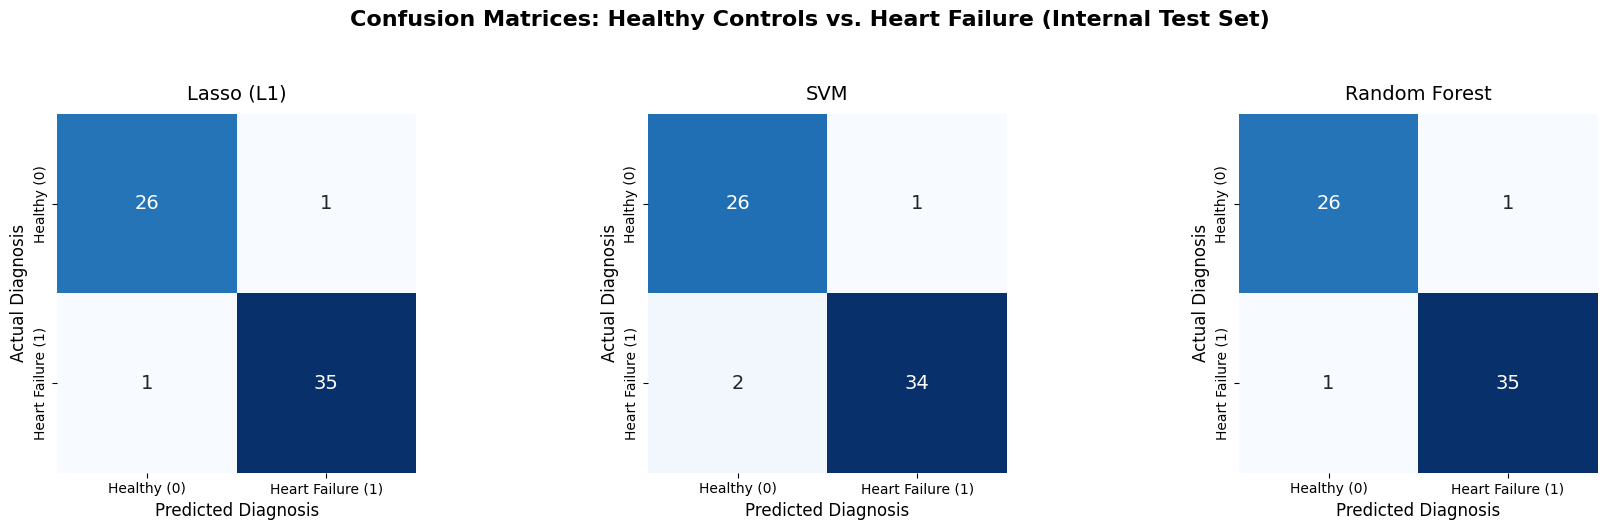

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Generating Confusion Matrices for all models...")

# Create a figure with 1 row and 3 columns (for Lasso, SVM, and RF)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices: Healthy Controls vs. Heart Failure (Internal Test Set)',
             fontsize=16, fontweight='bold', y=1.05)

# We want our labels to be extremely clear for the paper
class_labels = ['Healthy (0)', 'Heart Failure (1)']

# Loop through the models and plot each one
for i, (name, best_model) in enumerate(best_models.items()):

    # 1. Get the predictions for the test set
    y_pred = best_model.predict(X_test_scaled)

    # 2. Calculate the raw confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # 3. Plot it using seaborn heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, square=True,
                xticklabels=class_labels, yticklabels=class_labels,
                annot_kws={"size": 14}) # Make the numbers inside the boxes larger

    # 4. Add titles and labels
    axes[i].set_title(f'{name}', fontsize=14, pad=10)
    axes[i].set_xlabel('Predicted Diagnosis', fontsize=12)
    axes[i].set_ylabel('Actual Diagnosis', fontsize=12)

plt.tight_layout()
plt.show()

# Optional: Save for your manuscript
# plt.savefig(f"{RESULTS_DIR}/Model_Confusion_Matrices.png", dpi=300, bbox_inches='tight')

In [ ]:
# --- STEP 7: EXTERNAL VALIDATION (RQ3) ---
print("\n" + "="*50)
print("EXTERNAL VALIDATION: TESTING ON NEW DATASET")
print("="*50)

# 1. Load the external dataset
# Make sure this file has the same genes/columns as your training data!
try:
    df_external = pd.read_csv(f"{DATA_DIR}/GSE5406_Test_Padded.csv", index_col=0)

    # Separate features and target
    X_ext = df_external.drop(columns=['Target'])
    y_ext = df_external['Target']

    # 2. FEATURE ALIGNMENT
    # Ensure external features match the internal training features
    # This keeps only the columns that were in X_train and puts them in the same order
    X_ext_aligned = X_ext[X.columns]

    # 3. APPLY INTERNAL SCALING
    # DO NOT use .fit_transform()! Use .transform() only.
    X_ext_scaled = scaler.transform(X_ext_aligned)

    # 4. RUN PRE-TRAINED MODELS
    for name, best_model in best_models.items():
        print(f"\n--- {name}: External Performance ---")

        # Get binary predictions
        ext_pred = best_model.predict(X_ext_scaled)

        # Get probabilities for the positive class (Class 1) for AUC
        ext_prob = best_model.predict_proba(X_ext_scaled)[:, 1]

        # Calculate metrics
        ext_accuracy = accuracy_score(y_ext, ext_pred)
        ext_auc = roc_auc_score(y_ext, ext_prob)
        ext_mcc = matthews_corrcoef(y_ext, ext_pred)

        # Print results
        print(f"External Accuracy: {ext_accuracy * 100:.2f}%")
        print(f"External AUC Score: {ext_auc:.4f}")
        print(f"External MCC Score: {ext_mcc:.4f}")
        print(classification_report(y_ext, ext_pred))

except FileNotFoundError:
    print("External dataset file not found. Please check the filename.")
except KeyError as e:
    print(f"Feature Mismatch Error: The external dataset is missing gene: {e}")


EXTERNAL VALIDATION: TESTING ON NEW DATASET

--- Lasso (L1): External Performance ---
External Accuracy: 92.38%
External AUC Score: 0.9533
External MCC Score: 0.0000
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        16
           1       0.92      1.00      0.96       194

    accuracy                           0.92       210
   macro avg       0.46      0.50      0.48       210
weighted avg       0.85      0.92      0.89       210


--- SVM: External Performance ---
External Accuracy: 92.38%
External AUC Score: 0.9617
External MCC Score: 0.0000
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        16
           1       0.92      1.00      0.96       194

    accuracy                           0.92       210
   macro avg       0.46      0.50      0.48       210
weighted avg       0.85      0.92      0.89       210


--- Random Forest: External Performance ---
External Accuracy: 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m


GENERATING EXTERNAL CONFUSION MATRICES


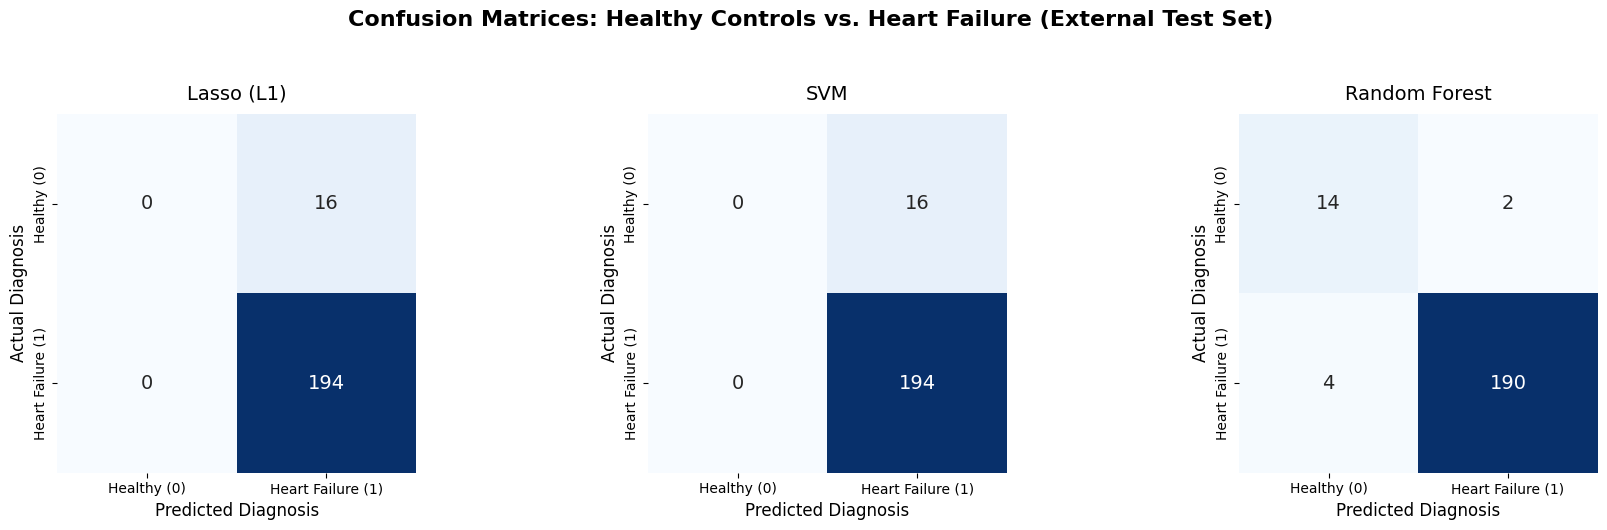

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("\n" + "="*50)
print("GENERATING EXTERNAL CONFUSION MATRICES")
print("="*50)

# Create a figure with 1 row and 3 columns (for Lasso, SVM, and RF)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices: Healthy Controls vs. Heart Failure (External Test Set)',
             fontsize=16, fontweight='bold', y=1.05)

# We want our labels to be extremely clear for the paper
class_labels = ['Healthy (0)', 'Heart Failure (1)']

# Loop through the models and plot each one
for i, (name, best_model) in enumerate(best_models.items()):

    # 1. Get the binary predictions for the EXTERNAL test set
    y_pred_ext = best_model.predict(X_ext_scaled)

    # 2. Calculate the raw confusion matrix using y_ext
    cm = confusion_matrix(y_ext, y_pred_ext)

    # 3. Plot it using seaborn heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, square=True,
                xticklabels=class_labels, yticklabels=class_labels,
                annot_kws={"size": 14}) # Make the numbers inside the boxes larger

    # 4. Add titles and labels
    axes[i].set_title(f'{name}', fontsize=14, pad=10)
    axes[i].set_xlabel('Predicted Diagnosis', fontsize=12)
    axes[i].set_ylabel('Actual Diagnosis', fontsize=12)

plt.tight_layout()
plt.show()

Initializing SHAP Explainers for all models...



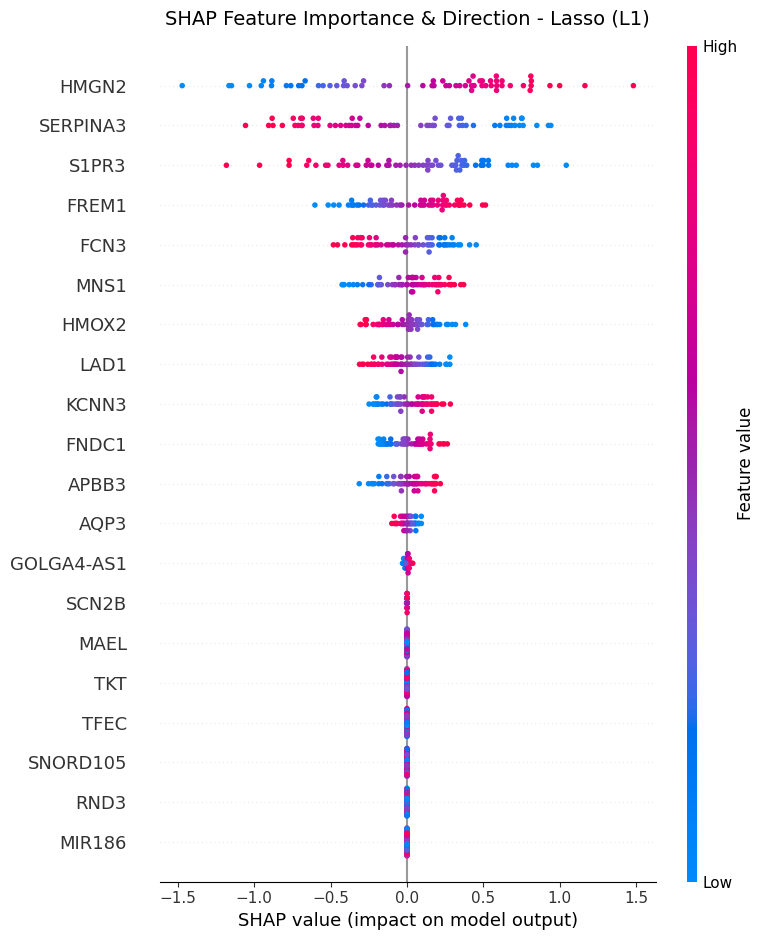

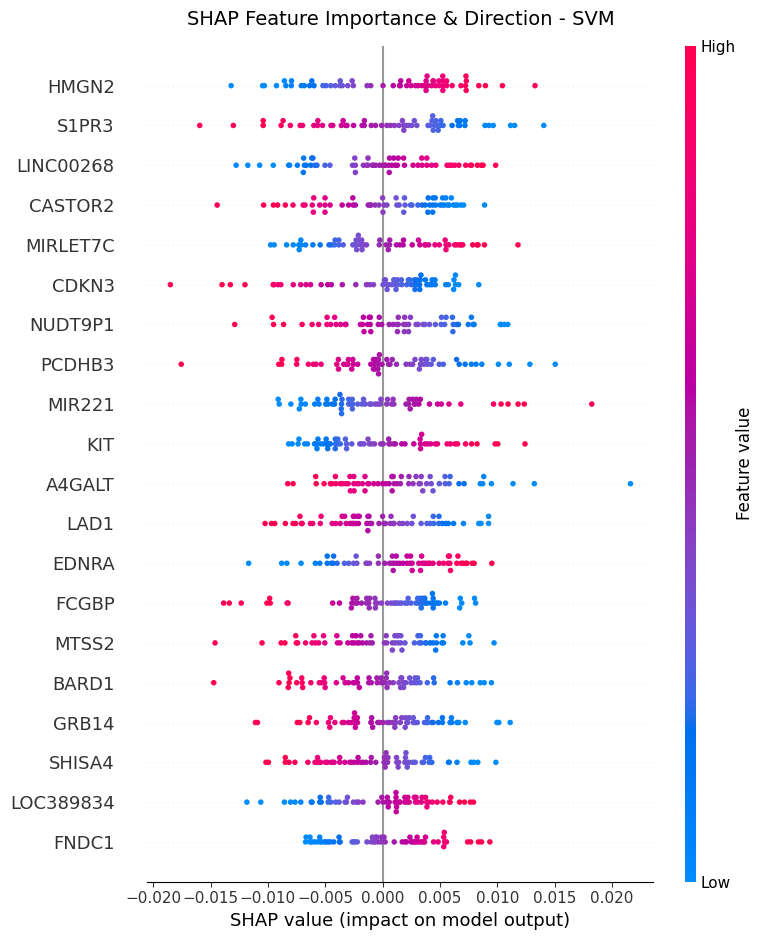

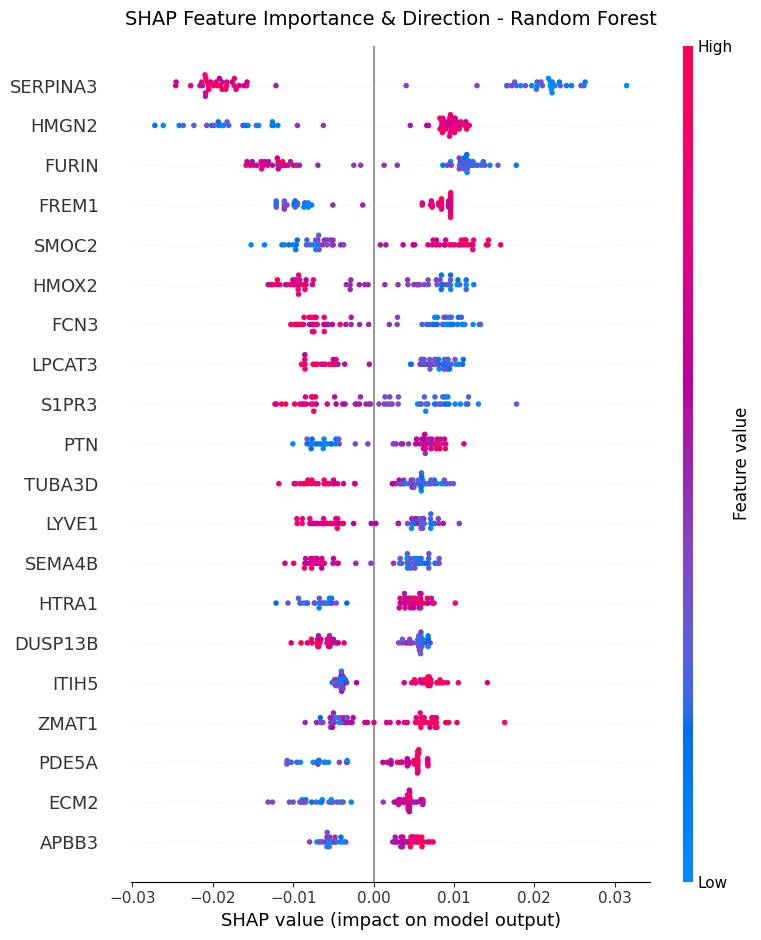

In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

print("Initializing SHAP Explainers for all models...\n")
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns)
X_train_df = pd.DataFrame(X_train_scaled, columns=X.columns)

for name, model in best_models.items():
    plt.figure(figsize=(10, 6))

    if name == "Random Forest":
        # Tree models use TreeExplainer
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test_df)

        # Scikit-learn RF outputs SHAP values for [Class 0, Class 1]. We want Class 1.
        if isinstance(shap_values, list):
            shap_vals_to_plot = shap_values[1]
        elif len(shap_values.shape) == 3:
            shap_vals_to_plot = shap_values[:, :, 1]
        else:
            shap_vals_to_plot = shap_values

    elif name == "Lasso (L1)":
        # Linear models need the background training data to calculate baseline expected values
        explainer = shap.LinearExplainer(model, X_train_df)
        shap_values = explainer.shap_values(X_test_df)
        shap_vals_to_plot = shap_values

    elif name == "SVM":
        # Because your best SVM uses a 'linear' kernel, LinearExplainer works perfectly here too
        explainer = shap.LinearExplainer(model, X_train_df)
        shap_values = explainer.shap_values(X_test_df)
        shap_vals_to_plot = shap_values

    # Generate the Beeswarm Plot
    plt.title(f"SHAP Feature Importance & Direction - {name}", fontsize=14, pad=15)

    shap.summary_plot(
        shap_vals_to_plot,
        X_test_df,
        max_display=20,  # Shows the top 20 genes for each model
        plot_type="dot", # This creates the beeswarm plot
        show=False
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import shap
import numpy as np
import pandas as pd

print("Initializing Dual-Dataset SHAP Consensus Evaluation...\n")

# The LinearExplainer ALWAYS needs the training data as its background baseline
X_train_df = pd.DataFrame(X_train_scaled, columns=X.columns)

# Prepare the two evaluation datasets
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns) # Internal Test Set
X_ext_df = pd.DataFrame(X_ext_scaled, columns=X.columns)   # External Validation Set

# --- STEP 2: CREATE A REUSABLE CONSENSUS FUNCTION ---
def calculate_shap_consensus(models_dict, background_df, eval_df, dataset_name, output_filename):
    print(f"-------------------------------------------------------")
    print(f"Calculating Global SHAP Consensus for: {dataset_name}")
    print(f"-------------------------------------------------------")

    # Initialize results table
    shap_importances = pd.DataFrame({'Gene': background_df.columns})

    # 1. Extract Mean Absolute SHAP values
    for name, model in models_dict.items():
        if name == "Random Forest":
            explainer = shap.TreeExplainer(model)
            shap_vals_raw = explainer.shap_values(eval_df)

            # Extract Class 1 for Scikit-Learn RF
            if isinstance(shap_vals_raw, list):
                shap_vals = shap_vals_raw[1]
            elif len(shap_vals_raw.shape) == 3:
                shap_vals = shap_vals_raw[:, :, 1]
            else:
                shap_vals = shap_vals_raw

        else: # Lasso and SVM (using LinearExplainer)
            explainer = shap.LinearExplainer(model, background_df)
            shap_vals = explainer.shap_values(eval_df)

        # Calculate global importance for this specific dataset
        mean_abs_shap = np.abs(shap_vals).mean(axis=0)
        shap_importances[f'{name}_Raw_SHAP'] = mean_abs_shap

    # 2. Min-Max Normalization (0 to 1 scale) with Zero-Division Safeguard
    def normalize_col(col):
        if col.max() == col.min():
            return np.zeros_like(col)
        return (col - col.min()) / (col.max() - col.min())

    shap_importances['Lasso_Norm'] = normalize_col(shap_importances['Lasso (L1)_Raw_SHAP'])
    shap_importances['SVM_Norm'] = normalize_col(shap_importances['SVM_Raw_SHAP'])
    shap_importances['RF_Norm'] = normalize_col(shap_importances['Random Forest_Raw_SHAP'])

    # 3. Calculate the Total SHAP Consensus Score (Max possible = 3.0)
    shap_importances['Total_SHAP_Consensus'] = (
        shap_importances['Lasso_Norm'] +
        shap_importances['SVM_Norm'] +
        shap_importances['RF_Norm']
    )

    # 4. Sort and isolate Top 25
    final_consensus = shap_importances.sort_values(by='Total_SHAP_Consensus', ascending=False).head(25)

    # 5. Display nicely in the console
    print(f"\n=== TOP 25 GENE SIGNATURE ({dataset_name}) ===")
    final_print_df = final_consensus.set_index('Gene')
    print(final_print_df[['Total_SHAP_Consensus', 'Lasso_Norm', 'SVM_Norm', 'RF_Norm']].round(4))

    # 6. Save to CSV
    final_consensus.to_csv(output_filename, index=False)
    print(f"\n[SAVED] {output_filename}\n")

    return final_consensus

# --- STEP 3: EXECUTE FOR BOTH DATASETS ---

# 1. Run Internal Test Consensus
internal_signature = calculate_shap_consensus(
    models_dict=best_models,
    background_df=X_train_df,
    eval_df=X_test_df,
    dataset_name="INTERNAL TEST SET",
    output_filename=f"{RESULTS_DIR}/Final_Master_SHAP_Consensus_Signature.csv"
)

# 2. Run External Validation Consensus
external_signature = calculate_shap_consensus(
    models_dict=best_models,
    background_df=X_train_df,
    eval_df=X_ext_df,
    dataset_name="EXTERNAL DATASET (GSE5406)",
    output_filename=f"{RESULTS_DIR}/External_SHAP_Consensus_Signature.csv"
)

print("=== PIPELINE COMPLETE ===")
print("Both Internal and External Consensus Signatures have been generated and saved!")

Initializing Dual-Dataset SHAP Consensus Evaluation...

-------------------------------------------------------
Calculating Global SHAP Consensus for: INTERNAL TEST SET
-------------------------------------------------------

=== TOP 25 GENE SIGNATURE (INTERNAL TEST SET) ===
           Total_SHAP_Consensus  Lasso_Norm  SVM_Norm  RF_Norm
Gene                                                          
HMGN2                    2.6328      1.0000    1.0000   0.6328
SERPINA3                 2.3109      0.8517    0.4592   1.0000
S1PR3                    2.0004      0.6640    0.9981   0.3383
FREM1                    1.3398      0.4149    0.4745   0.4503
LAD1                     1.1808      0.2115    0.7772   0.1920
FCN3                     1.1727      0.3643    0.4220   0.3863
HMOX2                    1.1192      0.2226    0.4883   0.4083
APBB3                    1.1027      0.1774    0.6775   0.2478
MNS1                     1.0138      0.2819    0.5302   0.2016
FURIN                    1.0092

In [ ]:
# --- STEP 4: CROSS-COHORT MASTER SIGNATURE (TOP 6) ---

print("CALCULATING FINAL CROSS-COHORT 6-GENE SIGNATURE")

# 1. Ensure 'Gene' is a column, not just the index
if 'Gene' not in internal_signature.columns:
    internal_signature = internal_signature.reset_index()
if 'Gene' not in external_signature.columns:
    external_signature = external_signature.reset_index()

# 2. Merge the Internal and External SHAP tables on the 'Gene' column
# An 'inner' join ensures we ONLY look at genes that exist and ranked in BOTH datasets
cross_cohort_df = pd.merge(
    internal_signature[['Gene', 'Total_SHAP_Consensus']],
    external_signature[['Gene', 'Total_SHAP_Consensus']],
    on='Gene',
    suffixes=('_Internal', '_External')
)

# 3. Calculate the Master Cross-Cohort Score
# Max possible score = 6.0 (3.0 from Internal + 3.0 from External)
cross_cohort_df['Cross_Cohort_Total'] = cross_cohort_df['Total_SHAP_Consensus_Internal'] + cross_cohort_df['Total_SHAP_Consensus_External']

# 4. Sort to find the absolute Top 6 most influential genes overall
top_6_master_signature = cross_cohort_df.sort_values(by='Cross_Cohort_Total', ascending=False).head(6)

# 5. Display the results beautifully
print("\n🏆 === TOP 6 UNIVERSAL DIAGNOSTIC PANEL === 🏆")
top_6_print = top_6_master_signature.set_index('Gene')
print(top_6_print.round(4))

# 6. Save to CSV
output_filename = f"{RESULTS_DIR}/Top_6_Cross_Cohort_Signature.csv"
top_6_master_signature.to_csv(output_filename, index=False)
print(f"\n[SUCCESS] Final Panel Saved to: '{output_filename}'")
print("Your Machine Learning Biomarker Discovery Pipeline is 100% Complete!")

PHACALCULATING FINAL CROSS-COHORT 6-GENE SIGNATURE

🏆 === TOP 6 UNIVERSAL DIAGNOSTIC PANEL === 🏆
          Total_SHAP_Consensus_Internal  Total_SHAP_Consensus_External  \
Gene                                                                     
S1PR3                            2.0004                         2.7500   
HMGN2                            2.6328                         1.0768   
SERPINA3                         2.3109                         1.0298   
FREM1                            1.3398                         1.2435   
LAD1                             1.1808                         0.7799   
HMOX2                            1.1192                         0.8065   

          Cross_Cohort_Total  
Gene                          
S1PR3                 4.7504  
HMGN2                 3.7096  
SERPINA3              3.3408  
FREM1                 2.5833  
LAD1                  1.9607  
HMOX2                 1.9257  

[SUCCESS] Final Panel Saved to: 'Top_6_Cross_Cohort_Signature

=== Generating Differentiated Comparative Visualization ===


/tmp/ipykernel_7835/319202893.py:70: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_7835/319202893.py:70: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_7835/319202893.py:70: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_7835/319202893.py:70: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_7835/319202893.py:70: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the s

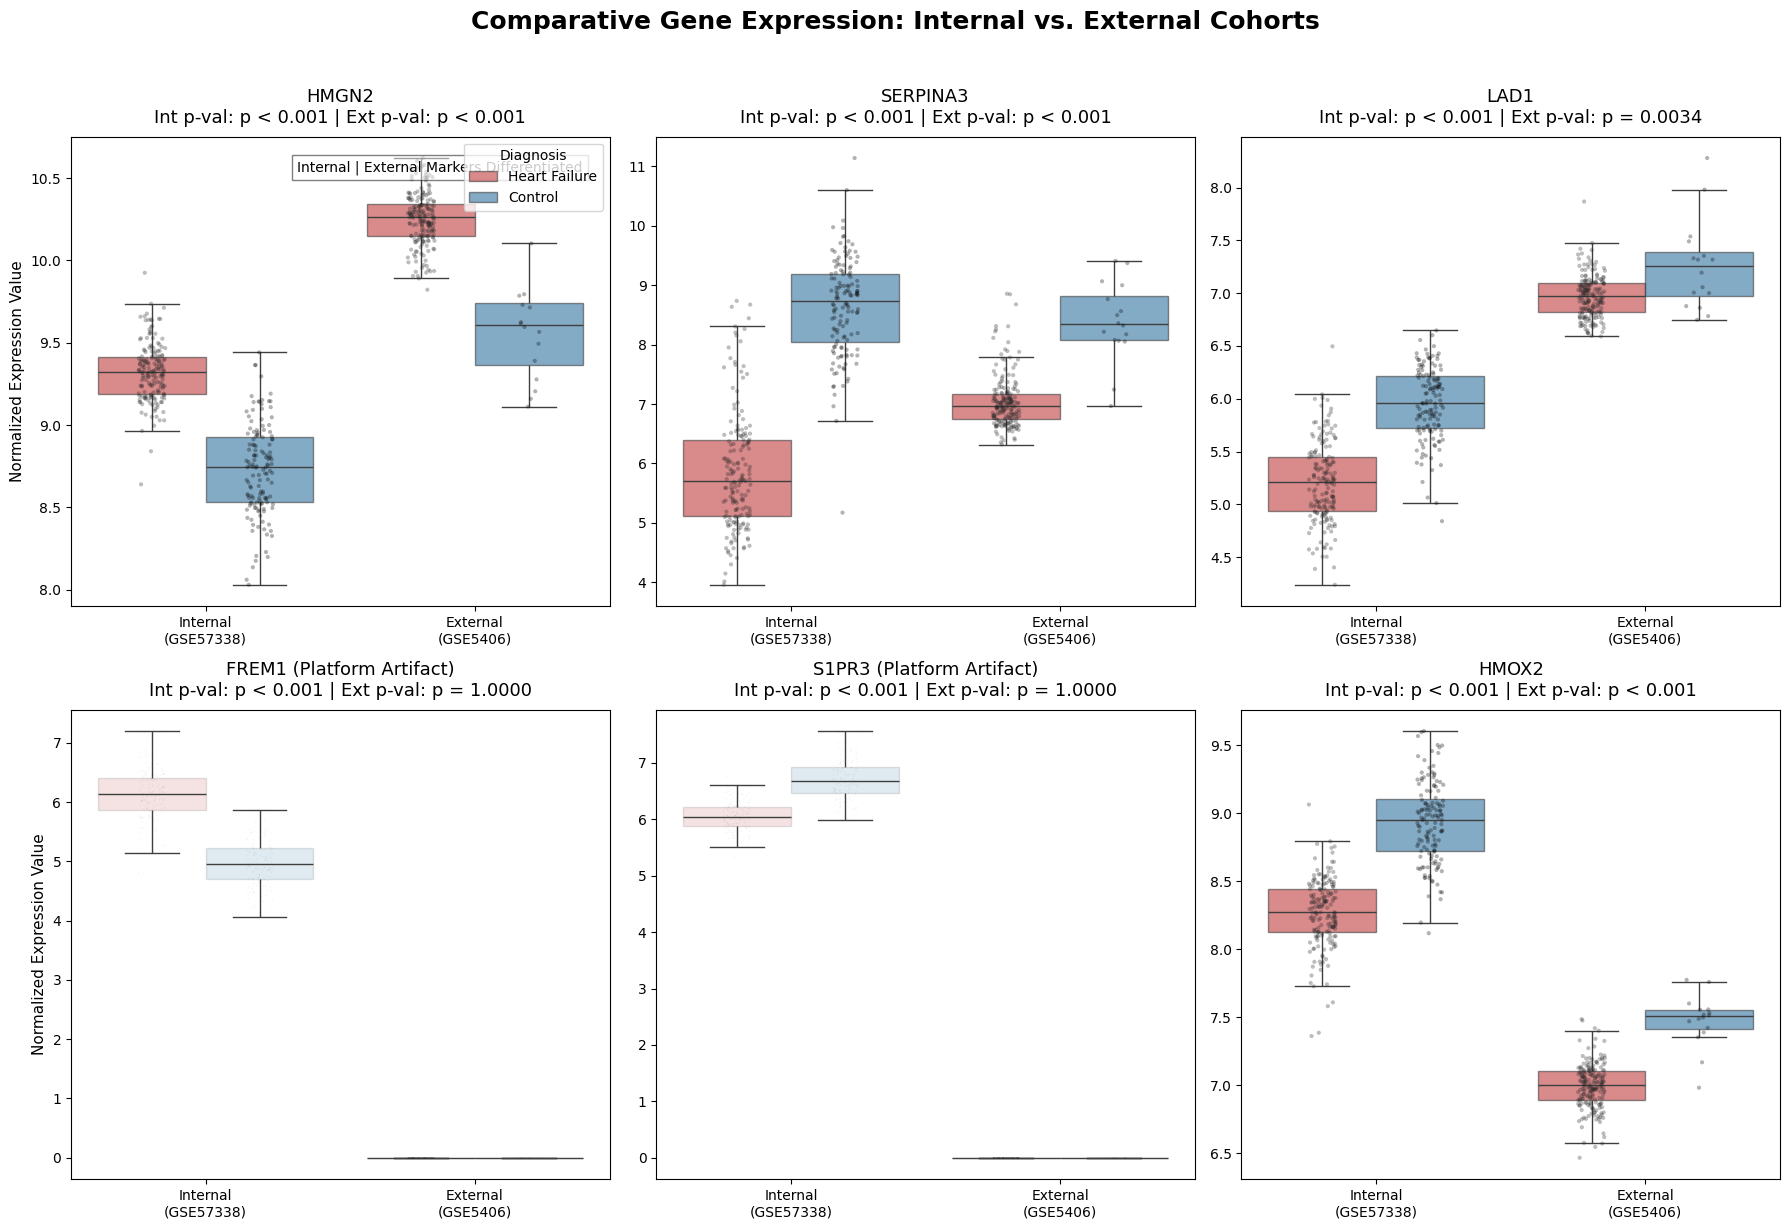

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

print("=== Generating Differentiated Comparative Visualization ===")

# 1. Define your top 6 genes to analyze (from RQ2 list)
top_genes = ['HMGN2', 'SERPINA3', 'LAD1', 'FREM1', 'S1PR3', 'HMOX2']
# A. Prepare Internal Data
exp_df = X[top_genes].copy()
exp_df['Condition'] = y.values
exp_df['Condition'] = exp_df['Condition'].map({0: 'Control', 1: 'Heart Failure'})
exp_df['Cohort'] = 'Internal\n(GSE57338)'

# B. Prepare External Data
exp_df_ext = X_ext[top_genes].copy()
exp_df_ext['Condition'] = y_ext.values
exp_df_ext['Condition'] = exp_df_ext['Condition'].map({0: 'Control', 1: 'Heart Failure'})
exp_df_ext['Cohort'] = 'External\n(GSE5406)'

# C. Combine both datasets vertically for comparative plotting
combined_df = pd.concat([exp_df, exp_df_ext], ignore_index=True)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Comparative Gene Expression: Internal vs. External Cohorts',
             fontsize=18, fontweight='bold', y=1.02)
axes = axes.flatten()

# 4. FIXED CLINICAL PALETTES
# Standard Condition hue logic for Boxplots: Blue vs Red
pal_boxes = {'Control': '#1f77b4', 'Heart Failure': '#d62728'}

# 6. Loop and plot with p-values
for i, gene in enumerate(top_genes):
    # Determine if this gene is an artifact (FREM1, S1PR3)
    is_artifact = gene in ['FREM1', 'S1PR3']

    # GHOSTING IMPROVEMENT (Alpha blending): Highly transparent if artifact
    box_alpha = 0.15 if is_artifact else 0.6
    # Fixed stripplot weight for better readability
    strip_alpha = 0.05 if is_artifact else 0.3
    strip_size = 1 if is_artifact else 3

    # A. Calculate Internal p-value
    c_int = combined_df[(combined_df['Condition'] == 'Control') & (combined_df['Cohort'] == 'Internal\n(GSE57338)')][gene]
    h_int = combined_df[(combined_df['Condition'] == 'Heart Failure') & (combined_df['Cohort'] == 'Internal\n(GSE57338)')][gene]
    _, p_int = mannwhitneyu(c_int, h_int, alternative='two-sided')
    p_int_txt = "p < 0.001" if p_int < 0.001 else f"p = {p_int:.4f}"

    # B. Calculate External p-value
    c_ext = combined_df[(combined_df['Condition'] == 'Control') & (combined_df['Cohort'] == 'External\n(GSE5406)')][gene]
    h_ext = combined_df[(combined_df['Condition'] == 'Heart Failure') & (combined_df['Cohort'] == 'External\n(GSE5406)')][gene]
    _, p_ext = mannwhitneyu(c_ext, h_ext, alternative='two-sided')
    p_ext_txt = "p < 0.001" if p_ext < 0.001 else f"p = {p_ext:.4f}"

    # C. Build Title
    title = f"{gene}"
    subtitle = f"Int p-val: {p_int_txt} | Ext p-val: {p_ext_txt}"
    if is_artifact:
        title += " (Platform Artifact)"

    # D. Boxplots (Cohort on X, Hue Diagnosis - The standard biological logic for boxes)
    sns.boxplot(
        x='Cohort', y=gene, hue='Condition', data=combined_df,
        ax=axes[i], palette=pal_boxes, # Core Blue/Red
        boxprops=dict(alpha=box_alpha), showfliers=False
    )

    # E. Stripplots (Cohort on X, Hue Diagnosis - Fixed overlays)
    sns.stripplot(
        x='Cohort', y=gene, hue='Condition', data=combined_df,
        ax=axes[i], dodge=True, color='black', alpha=strip_alpha, s=strip_size, jitter=True
    )

    # G. Formatting and legends cleanup
    axes[i].set_title(f"{title}\n{subtitle}", fontsize=13, pad=10)
    axes[i].set_ylabel('Normalized Expression Value' if i % 3 == 0 else '', fontsize=11)
    axes[i].set_xlabel('')

    # Clean up duplicate legends and provide key to Differentiated Cohort Points
    handles, labels = axes[i].get_legend_handles_labels()
    if i == 0:
        # Create a unified legend
        # Filter for unique Diagnosis handles
        unique_handles = list(pal_boxes.values())
        axes[i].legend(handles[:2], labels[:2], title='Diagnosis', loc='upper right', frameon=True, fontsize=10)
        # We can also add a subtle text legend noting the cohort differentiation.
        axes[i].text(0.95, 0.95, "Internal | External Markers Differentiated", transform=axes[i].transAxes,
                     fontsize=10, ha='right', va='top', bbox=dict(facecolor='white', alpha=0.5))
    else:
        # Remove legends from all other subplots to keep it clean
        if axes[i].legend_ is not None:
            axes[i].legend_.remove()

plt.tight_layout()

# Optional: Save for your manuscript
# plt.savefig(f"{RESULTS_DIR}/Gene_Expression_Boxplots.png", dpi=300, bbox_inches='tight')

plt.show()